# IEEE-CIS fraud detection: exploration and training experiments

Research question: How do model choice, transaction features, identity information, and simple feature engineering affect fraud detection?

This notebook documents the completed experiments. **No rerun is needed.** Saved outputs are historical results from the original notebook, not newly executed results. Execution counts have been cleared during organization.

Use `02_saved_model_evaluation.ipynb` for evaluation without training. Running this notebook reproduces all experiments and may take many hours. The next cell deliberately stops execution unless you opt in.

Protocol: chronological 70/15/15 split; preprocessing learned on training data; model selection and early stopping by validation ROC-AUC; threshold selection by validation F1. Kaggle test data and submissions are outside this project scope.

In [ ]:
RUN_TRAINING = False
if not RUN_TRAINING:
    raise RuntimeError("Training disabled. Read existing outputs or open 02_saved_model_evaluation.ipynb. Set RUN_TRAINING=True only to deliberately reproduce all experiments.")

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path("C:/Users/caleb/OneDrive/Documents/UARK Classes/Fall2026/Data_Mining/ieee-fraud-project")
DATA_DIR = PROJECT_DIR / "data"
for name in ["train_transaction.csv", "train_identity.csv"]:
    assert (DATA_DIR / name).is_file(), f"Missing file: {name}"
print("Training files found.")

Training files found.


## 1. Load transactions
Each row is a transaction. `isFraud` is the target: 1 means fraud and 0 means legitimate. `head()` displays the first five rows; it does not limit the data loaded.

In [ ]:
transactions = pd.read_csv(DATA_DIR / "train_transaction.csv")
print(f"Transactions: {transactions.shape[0]:,}")
print(f"Columns: {transactions.shape[1]:,}")
display(transactions.head())

Transactions: 590,540
Columns: 394


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Inspect the labels
How common is fraud? A model predicting legitimate for every transaction catches no fraud, even if its accuracy looks high.

In [ ]:
assert transactions["TransactionID"].is_unique
assert transactions["isFraud"].notna().all()
assert set(transactions["isFraud"].unique()) == {0, 1}
counts = transactions["isFraud"].value_counts().sort_index()
summary = pd.DataFrame({"count": counts, "percent": counts / len(transactions) * 100})
summary.index = summary.index.map({0: "Legitimate", 1: "Fraud"})
display(summary)
print(f"Always predicting legitimate: {(transactions['isFraud'] == 0).mean():.2%} accuracy")

,count,percent
isFraud,,
Legitimate,569877,96.500999
Fraud,20663,3.499001


Always predicting legitimate: 96.50% accuracy


## 3. Join the identity data
A left join preserves every transaction, including those with no matching identity record. The one-to-one validation prevents duplicate IDs from silently multiplying rows. Missing identity fields are expected.

In [ ]:
identity = pd.read_csv(DATA_DIR / "train_identity.csv")
assert identity["TransactionID"].is_unique
coverage = transactions["TransactionID"].isin(identity["TransactionID"]).mean()
print(f"Identity rows: {len(identity):,}")
print(f"Transactions with identity records: {coverage:.2%}")
train = transactions.merge(identity, on="TransactionID", how="left", validate="one_to_one")
assert len(train) == len(transactions)
print(f"Joined data: {train.shape[0]:,} rows and {train.shape[1]:,} columns")
display(train.head())
# Release the separate tables after joining.
del transactions, identity

Identity rows: 144,233
Transactions with identity records: 24.42%
Joined data: 590,540 rows and 434 columns


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


## 4. Inspect missing values
These are the 20 columns with the most missing values. We are not filling them yet. Later, preprocessing rules must be learned only from the training partition.

In [ ]:
missing_percent = train.isna().mean().mul(100).sort_values(ascending=False)
display(missing_percent.head(20).rename("missing_percent").to_frame())

,missing_percent
id_24,99.196159
id_25,99.130965
id_07,99.127070
id_08,99.127070
id_21,99.126393
id_26,99.125715
id_27,99.124699
id_23,99.124699
id_22,99.124699
dist2,93.628374


## Chronological evaluation split

In [ ]:
# Check that every transaction has a time value.
assert train["TransactionDT"].notna().all()

# Sort from earliest to latest.
ordered = train.sort_values("TransactionDT").reset_index(drop=True)

# Choose time boundaries near the 70% and 85% positions.
n = len(ordered)
validation_start = ordered.iloc[int(n * 0.70)]["TransactionDT"]
holdout_start = ordered.iloc[int(n * 0.85)]["TransactionDT"]

# Keep transactions with identical time values in the same partition.
train_df = ordered.loc[
    ordered["TransactionDT"] < validation_start
].copy()

val_df = ordered.loc[
    (ordered["TransactionDT"] >= validation_start)
    & (ordered["TransactionDT"] < holdout_start)
].copy()

holdout_df = ordered.loc[
    ordered["TransactionDT"] >= holdout_start
].copy()

# Verify that all rows are accounted for and time ranges do not overlap.
assert len(train_df) + len(val_df) + len(holdout_df) == n
assert min(len(train_df), len(val_df), len(holdout_df)) > 0
assert train_df["TransactionDT"].max() < val_df["TransactionDT"].min()
assert val_df["TransactionDT"].max() < holdout_df["TransactionDT"].min()

# Inspect partition sizes and label balance.
split_summary = pd.DataFrame([
    {
        "partition": name,
        "transactions": len(part),
        "percent_of_data": len(part) / n * 100,
        "fraud_count": int(part["isFraud"].sum()),
        "fraud_percent": part["isFraud"].mean() * 100,
    }
    for name, part in [
        ("Training", train_df),
        ("Validation", val_df),
        ("Holdout", holdout_df),
    ]
]).set_index("partition")

display(split_summary.round(2))

# Release redundant full-data tables to reduce memory use.
del ordered, train

,transactions,percent_of_data,fraud_count,fraud_percent
partition,,,,
Training,413378,70.0,14538,3.52
Validation,88581,15.0,3042,3.43
Holdout,88581,15.0,3083,3.48


## Training-only exploration: product categories

,transaction_count,fraud_count,fraud_percent
ProductCD,,,
C,50006,5588,11.17
S,7205,435,6.04
H,28112,1270,4.52
R,30144,1054,3.50
W,297911,6191,2.08


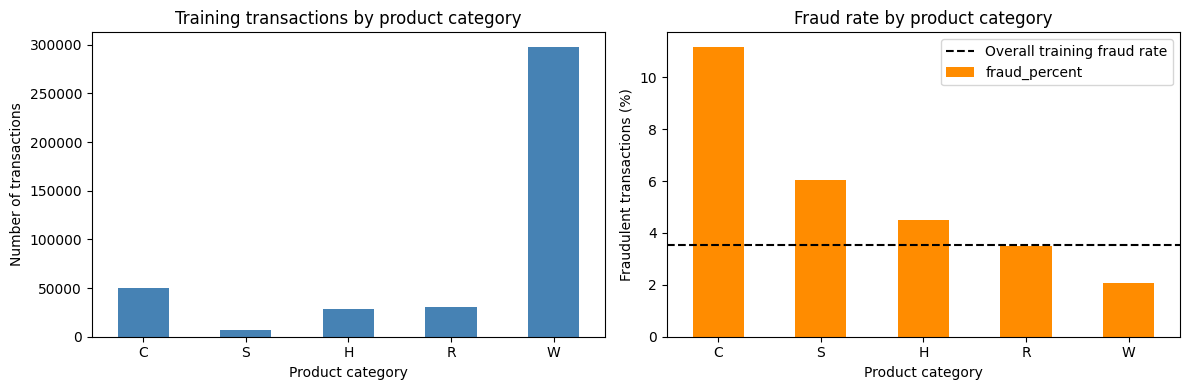

In [ ]:
import matplotlib.pyplot as plt

# Summarize each product category using only the training partition.
product_summary = (
    train_df.groupby("ProductCD", dropna=False)["isFraud"]
    .agg(
        transaction_count="size",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

product_summary["fraud_percent"] = product_summary["fraud_rate"] * 100
product_summary = product_summary.sort_values(
    "fraud_percent", ascending=False
)

display(
    product_summary[
        ["transaction_count", "fraud_count", "fraud_percent"]
    ].round(2)
)

# Show category size beside fraud prevalence.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

product_summary["transaction_count"].plot.bar(
    ax=axes[0], color="steelblue"
)
axes[0].set_title("Training transactions by product category")
axes[0].set_xlabel("Product category")
axes[0].set_ylabel("Number of transactions")
axes[0].tick_params(axis="x", rotation=0)

product_summary["fraud_percent"].plot.bar(
    ax=axes[1], color="darkorange"
)
axes[1].axhline(
    train_df["isFraud"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall training fraud rate"
)
axes[1].set_title("Fraud rate by product category")
axes[1].set_xlabel("Product category")
axes[1].set_ylabel("Fraudulent transactions (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend()

plt.tight_layout()
plt.show()

## Training-only exploration: transaction amounts

In [ ]:
# Summarize transaction amounts separately for each class.
amount_summary = (
    train_df.groupby("isFraud")["TransactionAmt"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .rename(index={0: "Legitimate", 1: "Fraud"})
)

display(amount_summary.round(2))

,count,mean,std,min,25%,50%,75%,95%,99%,max
isFraud,,,,,,,,,,
Legitimate,398840.0,134.20,238.76,0.25,43.95,68.95,125.0,437.0,1104.0,31937.39
Fraud,14538.0,145.64,216.15,0.29,34.75,75.00,171.0,490.0,994.0,4191.00


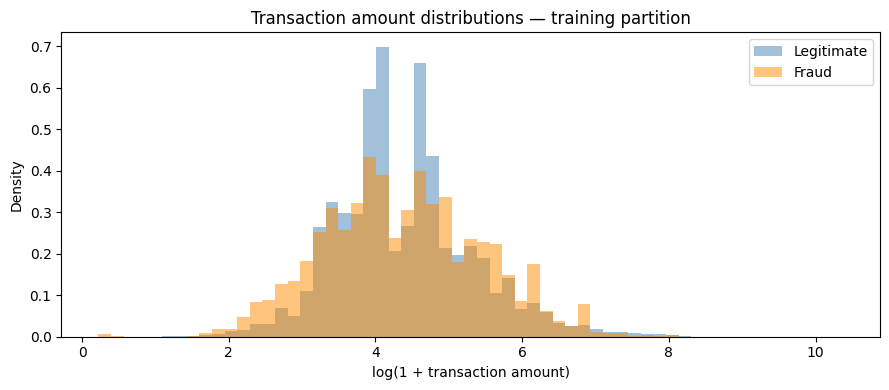

In [ ]:
import numpy as np

# Check amounts before applying a logarithmic transformation.
amounts = train_df["TransactionAmt"]
assert amounts.dropna().ge(0).all()

# Shared bins make the two distributions directly comparable.
log_amounts = np.log1p(amounts.dropna())
bins = np.linspace(log_amounts.min(), log_amounts.max(), 60)

fig, ax = plt.subplots(figsize=(9, 4))

for label, name, color in [
    (0, "Legitimate", "steelblue"),
    (1, "Fraud", "darkorange"),
]:
    values = train_df.loc[
        train_df["isFraud"] == label, "TransactionAmt"
    ].dropna()

    ax.hist(
        np.log1p(values),
        bins=bins,
        density=True,
        alpha=0.5,
        label=name,
        color=color
    )

ax.set_title("Transaction amount distributions — training partition")
ax.set_xlabel("log(1 + transaction amount)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

## Dummy baseline

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
)

# The target is kept separate from model inputs.
y_train = train_df["isFraud"]
y_val = val_df["isFraud"]

# DummyClassifier ignores these feature values.
X_dummy_train = np.zeros((len(train_df), 1))
X_dummy_val = np.zeros((len(val_df), 1))

dummy = DummyClassifier(strategy="prior")
dummy.fit(X_dummy_train, y_train)

# Probability of fraud, rather than the predicted class.
dummy_prob = dummy.predict_proba(X_dummy_val)[:, 1]

# Convert probabilities into labels using a 0.5 threshold.
dummy_pred = (dummy_prob >= 0.5).astype(int)

baseline_results = pd.DataFrame([{
    "model": "Dummy baseline",
    "roc_auc": roc_auc_score(y_val, dummy_prob),
    "average_precision": average_precision_score(y_val, dummy_prob),
    "accuracy": accuracy_score(y_val, dummy_pred),
    "precision": precision_score(y_val, dummy_pred, zero_division=0),
    "recall": recall_score(y_val, dummy_pred, zero_division=0),
}])

display(baseline_results.round(4))
print(f"Probability assigned to every transaction: {dummy_prob[0]:.4f}")

,model,roc_auc,average_precision,accuracy,precision,recall
0,Dummy baseline,0.5,0.0343,0.9657,0.0,0.0


Probability assigned to every transaction: 0.0352


## Logistic regression with selected features

In [ ]:
numeric_features = [
    "TransactionAmt",
    "dist1",
    "dist2",
]

categorical_features = [
    "ProductCD",
    "card4",
    "card6",
    "P_emaildomain",
    "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9",
]

features = numeric_features + categorical_features

X_train = train_df[features].copy()
X_val = val_df[features].copy()

y_train = train_df["isFraud"]
y_val = val_df["isFraud"]

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)

Training input shape: (413378, 17)
Validation input shape: (88581, 17)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=1000
    )),
])

logistic_model.fit(X_train, y_train)

print("Logistic regression training complete.")

Logistic regression training complete.


In [ ]:
logistic_prob = logistic_model.predict_proba(X_val)[:, 1]
logistic_pred = (logistic_prob >= 0.5).astype(int)

logistic_results = pd.DataFrame([{
    "model": "Logistic regression — selected features",
    "roc_auc": roc_auc_score(y_val, logistic_prob),
    "average_precision": average_precision_score(y_val, logistic_prob),
    "accuracy": accuracy_score(y_val, logistic_pred),
    "precision": precision_score(
        y_val, logistic_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, logistic_pred, zero_division=0
    ),
}])

results = pd.concat(
    [baseline_results, logistic_results],
    ignore_index=True
)

display(results.round(4))
print(f"Transactions flagged as fraud: {logistic_pred.sum():,}")

,model,roc_auc,average_precision,accuracy,precision,recall
0,Dummy baseline,0.5000,0.0343,0.9657,0.0,0.000
1,Logistic regression — selected features,0.7972,0.1685,0.9657,0.5,0.002


Transactions flagged as fraud: 12


## Threshold tradeoffs on validation data

In [ ]:
from sklearn.metrics import f1_score

threshold_rows = []

for threshold in [0.50, 0.20, 0.10, 0.05, 0.02]:
    predictions = (logistic_prob >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "flagged": int(predictions.sum()),
        "fraud_caught": int(
            ((predictions == 1) & (y_val.to_numpy() == 1)).sum()
        ),
        "false_alarms": int(
            ((predictions == 1) & (y_val.to_numpy() == 0)).sum()
        ),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,threshold,flagged,fraud_caught,false_alarms,precision,recall,f1
0,0.50,12,6,6,0.5000,0.0020,0.0039
1,0.20,1739,502,1237,0.2887,0.1650,0.2100
2,0.10,6985,1239,5746,0.1774,0.4073,0.2471
3,0.05,15359,1784,13575,0.1162,0.5865,0.1939
4,0.02,40439,2534,37905,0.0627,0.8330,0.1166


In [ ]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val, logistic_prob
)

# The final precision/recall pair has no corresponding threshold.
precision_values = precision_values[:-1]
recall_values = recall_values[:-1]

f1_values = np.divide(
    2 * precision_values * recall_values,
    precision_values + recall_values,
    out=np.zeros_like(precision_values),
    where=(precision_values + recall_values) > 0
)

best_index = np.argmax(f1_values)
logistic_threshold = float(thresholds[best_index])

print(f"Selected validation threshold: {logistic_threshold:.6f}")
print(f"Validation precision: {precision_values[best_index]:.4f}")
print(f"Validation recall:    {recall_values[best_index]:.4f}")
print(f"Validation F1:        {f1_values[best_index]:.4f}")

Selected validation threshold: 0.122080
Validation precision: 0.2302
Validation recall:    0.2870
Validation F1:        0.2554


Environment setup, only if packages are missing: run `%pip install pandas numpy scikit-learn catboost matplotlib ipykernel` in a separate cell. Recorded package versions are in `results/environment_versions.json`.

## CatBoost with the same selected features

In [ ]:
from catboost import CatBoostClassifier

# Use the same features and chronological split as logistic regression.
X_train_cb = train_df[features].copy()
X_val_cb = val_df[features].copy()

# CatBoost expects categorical values to be strings or integers.
# Represent missing categories explicitly.
for column in categorical_features:
    X_train_cb[column] = (
        X_train_cb[column].fillna("Missing").astype(str)
    )
    X_val_cb[column] = (
        X_val_cb[column].fillna("Missing").astype(str)
    )

# Numeric missing values remain NaN; CatBoost can handle them.
print("Training input shape:", X_train_cb.shape)
print("Validation input shape:", X_val_cb.shape)

Training input shape: (413378, 17)
Validation input shape: (88581, 17)


In [ ]:
catboost_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	test: 0.5480796	best: 0.5480796 (0)	total: 1.26s	remaining: 21m 3s
100:	test: 0.7985476	best: 0.7985476 (100)	total: 1m 29s	remaining: 13m 17s
200:	test: 0.8125157	best: 0.8125157 (200)	total: 3m 6s	remaining: 12m 22s
300:	test: 0.8165842	best: 0.8165842 (300)	total: 4m 44s	remaining: 11m
400:	test: 0.8195427	best: 0.8195427 (400)	total: 6m 25s	remaining: 9m 36s
500:	test: 0.8205701	best: 0.8206128 (499)	total: 8m 6s	remaining: 8m 4s
600:	test: 0.8215335	best: 0.8215716 (597)	total: 9m 44s	remaining: 6m 28s
700:	test: 0.8227247	best: 0.8227580 (697)	total: 11m 22s	remaining: 4m 50s
800:	test: 0.8232847	best: 0.8233210 (795)	total: 13m	remaining: 3m 13s
900:	test: 0.8235520	best: 0.8236052 (894)	total: 14m 42s	remaining: 1m 36s
999:	test: 0.8238555	best: 0.8238972 (953)	total: 16m 21s	remaining: 0us

bestTest = 0.8238971552
bestIteration = 953

Shrink model to first 954 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=4, verbose=100)

In [ ]:
catboost_prob = catboost_model.predict_proba(X_val_cb)[:, 1]
catboost_pred = (catboost_prob >= 0.5).astype(int)

catboost_results = pd.DataFrame([{
    "model": "CatBoost — selected features",
    "roc_auc": roc_auc_score(y_val, catboost_prob),
    "average_precision": average_precision_score(y_val, catboost_prob),
    "accuracy": accuracy_score(y_val, catboost_pred),
    "precision": precision_score(
        y_val, catboost_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, catboost_pred, zero_division=0
    ),
}])

results = pd.concat(
    [baseline_results, logistic_results, catboost_results],
    ignore_index=True
)

display(results.round(4))
print("Best iteration:", catboost_model.get_best_iteration())

,model,roc_auc,average_precision,accuracy,precision,recall
0,Dummy baseline,0.5000,0.0343,0.9657,0.0000,0.0000
1,Logistic regression — selected features,0.7972,0.1685,0.9657,0.5000,0.0020
2,CatBoost — selected features,0.8239,0.2185,0.9661,0.6881,0.0247


Best iteration: 953


## Reusable validation threshold selection

In [ ]:
def evaluate_at_best_f1(model_name, y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    # The last precision/recall pair has no threshold.
    precision = precision[:-1]
    recall = recall[:-1]

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0
    )

    best_index = np.argmax(f1)
    threshold = float(thresholds[best_index])
    predictions = (probabilities >= threshold).astype(int)
    actual = np.asarray(y_true)

    row = {
        "model": model_name,
        "threshold": threshold,
        "roc_auc": roc_auc_score(actual, probabilities),
        "average_precision": average_precision_score(
            actual, probabilities
        ),
        "precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "f1": f1_score(actual, predictions, zero_division=0),
        "flagged": int(predictions.sum()),
        "fraud_caught": int(
            ((predictions == 1) & (actual == 1)).sum()
        ),
        "false_alarms": int(
            ((predictions == 1) & (actual == 0)).sum()
        ),
    }

    return threshold, row


logistic_threshold, logistic_tuned_row = evaluate_at_best_f1(
    "Logistic regression — selected features",
    y_val,
    logistic_prob
)

catboost_threshold, catboost_tuned_row = evaluate_at_best_f1(
    "CatBoost — selected features",
    y_val,
    catboost_prob
)

tuned_results = pd.DataFrame([
    logistic_tuned_row,
    catboost_tuned_row,
])

display(tuned_results.round(4))

,model,threshold,roc_auc,average_precision,precision,recall,f1,flagged,fraud_caught,false_alarms
0,Logistic regression — selected features,0.1221,0.7972,0.1685,0.2302,0.2870,0.2554,3793,873,2920
1,CatBoost — selected features,0.1421,0.8239,0.2185,0.2895,0.3087,0.2988,3244,939,2305


## Expanded transaction feature experiment

In [ ]:
transaction_columns = pd.read_csv(
    DATA_DIR / "train_transaction.csv",
    nrows=0
).columns.tolist()

transaction_features = [
    column for column in transaction_columns
    if column not in ["TransactionID", "isFraud"]
]

# Some categorical variables have numeric storage types.
declared_transaction_categories = [
    "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2",
    "P_emaildomain", "R_emaildomain",
    *[f"M{i}" for i in range(1, 10)],
]

transaction_cat_features = [
    column for column in transaction_features
    if (
        column in declared_transaction_categories
        or pd.api.types.is_object_dtype(train_df[column])
        or isinstance(train_df[column].dtype, pd.CategoricalDtype)
    )
]

def prepare_catboost_inputs(frame, feature_names, category_names):
    prepared = frame[feature_names].copy()

    for column in category_names:
        prepared[column] = (
            prepared[column]
            .astype("string")
            .fillna("Missing")
            .astype(str)
        )

    return prepared

X_train_transaction = prepare_catboost_inputs(
    train_df, transaction_features, transaction_cat_features
)

X_val_transaction = prepare_catboost_inputs(
    val_df, transaction_features, transaction_cat_features
)

print("Transaction features:", len(transaction_features))
print("Categorical features:", len(transaction_cat_features))
print("Training shape:", X_train_transaction.shape)

Transaction features: 392
Categorical features: 20
Training shape: (413378, 392)


In [ ]:
transaction_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

transaction_model.fit(
    X_train_transaction,
    y_train,
    cat_features=transaction_cat_features,
    eval_set=(X_val_transaction, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	test: 0.6105410	best: 0.6105410 (0)	total: 1.69s	remaining: 28m 7s
100:	test: 0.8998777	best: 0.8999472 (99)	total: 2m 42s	remaining: 24m 3s
200:	test: 0.9122833	best: 0.9123626 (198)	total: 5m 22s	remaining: 21m 23s
300:	test: 0.9180088	best: 0.9180088 (300)	total: 8m 1s	remaining: 18m 38s
400:	test: 0.9200698	best: 0.9200714 (397)	total: 10m 39s	remaining: 15m 55s
500:	test: 0.9217410	best: 0.9217410 (500)	total: 13m 19s	remaining: 13m 16s
600:	test: 0.9233865	best: 0.9234129 (598)	total: 15m 59s	remaining: 10m 37s
700:	test: 0.9240313	best: 0.9241182 (692)	total: 18m 40s	remaining: 7m 57s
800:	test: 0.9255384	best: 0.9255560 (797)	total: 21m 19s	remaining: 5m 17s
900:	test: 0.9265775	best: 0.9265901 (896)	total: 23m 59s	remaining: 2m 38s
999:	test: 0.9270039	best: 0.9270426 (996)	total: 26m 35s	remaining: 0us

bestTest = 0.927042564
bestIteration = 996

Shrink model to first 997 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=4, verbose=100)

In [ ]:
transaction_prob = transaction_model.predict_proba(
    X_val_transaction
)[:, 1]

transaction_threshold, transaction_tuned_row = evaluate_at_best_f1(
    "CatBoost — all transaction features",
    y_val,
    transaction_prob
)

tuned_results = pd.DataFrame([
    logistic_tuned_row,
    catboost_tuned_row,
    transaction_tuned_row,
])

display(tuned_results.round(4))
print("Best iteration:", transaction_model.get_best_iteration())

,model,threshold,roc_auc,average_precision,precision,recall,f1,flagged,fraud_caught,false_alarms
0,Logistic regression — selected features,0.1221,0.7972,0.1685,0.2302,0.2870,0.2554,3793,873,2920
1,CatBoost — selected features,0.1421,0.8239,0.2185,0.2895,0.3087,0.2988,3244,939,2305
2,CatBoost — all transaction features,0.2305,0.9270,0.6248,0.6873,0.5391,0.6043,2386,1640,746


Best iteration: 996


## Identity feature experiment

In [ ]:
identity_columns = pd.read_csv(
    DATA_DIR / "train_identity.csv",
    nrows=0
).columns.tolist()

identity_features = [
    column for column in identity_columns
    if column != "TransactionID"
]

combined_features = transaction_features + identity_features

# These identity fields represent categories, even where stored numerically.
declared_identity_categories = [
    "DeviceType",
    "DeviceInfo",
    *[f"id_{i}" for i in range(12, 39)],
]

combined_cat_features = [
    column for column in combined_features
    if (
        column in transaction_cat_features
        or column in declared_identity_categories
        or pd.api.types.is_object_dtype(train_df[column])
        or isinstance(train_df[column].dtype, pd.CategoricalDtype)
    )
]

X_train_combined = prepare_catboost_inputs(
    train_df, combined_features, combined_cat_features
)

X_val_combined = prepare_catboost_inputs(
    val_df, combined_features, combined_cat_features
)

print("Total features:", len(combined_features))
print("Identity features added:", len(identity_features))
print("Categorical features:", len(combined_cat_features))

Total features: 432
Identity features added: 40
Categorical features: 49


In [ ]:
combined_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

combined_model.fit(
    X_train_combined,
    y_train,
    cat_features=combined_cat_features,
    eval_set=(X_val_combined, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	test: 0.6982673	best: 0.6982673 (0)	total: 3.49s	remaining: 58m 5s
100:	test: 0.9010235	best: 0.9010235 (100)	total: 5m 14s	remaining: 46m 39s
200:	test: 0.9121729	best: 0.9121729 (200)	total: 10m 26s	remaining: 41m 29s
300:	test: 0.9171193	best: 0.9171193 (300)	total: 15m 35s	remaining: 36m 13s
400:	test: 0.9205341	best: 0.9205341 (400)	total: 20m 52s	remaining: 31m 11s
500:	test: 0.9240945	best: 0.9240945 (500)	total: 26m 2s	remaining: 25m 55s
600:	test: 0.9252268	best: 0.9252463 (578)	total: 31m 6s	remaining: 20m 39s
700:	test: 0.9268357	best: 0.9268357 (700)	total: 36m 14s	remaining: 15m 27s
800:	test: 0.9283082	best: 0.9283082 (800)	total: 41m 28s	remaining: 10m 18s
900:	test: 0.9294088	best: 0.9294253 (889)	total: 46m 42s	remaining: 5m 7s
999:	test: 0.9299637	best: 0.9299637 (999)	total: 51m 57s	remaining: 0us

bestTest = 0.9299636895
bestIteration = 999



CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=4, verbose=100)

In [ ]:
combined_prob = combined_model.predict_proba(
    X_val_combined
)[:, 1]

combined_threshold, combined_tuned_row = evaluate_at_best_f1(
    "CatBoost — transaction + identity",
    y_val,
    combined_prob
)

tuned_results = pd.DataFrame([
    logistic_tuned_row,
    catboost_tuned_row,
    transaction_tuned_row,
    combined_tuned_row,
])

display(tuned_results.round(4))
print("Best iteration:", combined_model.get_best_iteration())

,model,threshold,roc_auc,average_precision,precision,recall,f1,flagged,fraud_caught,false_alarms
0,Logistic regression — selected features,0.1221,0.7972,0.1685,0.2302,0.2870,0.2554,3793,873,2920
1,CatBoost — selected features,0.1421,0.8239,0.2185,0.2895,0.3087,0.2988,3244,939,2305
2,CatBoost — all transaction features,0.2305,0.9270,0.6248,0.6873,0.5391,0.6043,2386,1640,746
3,CatBoost — transaction + identity,0.2057,0.9300,0.6363,0.6836,0.5496,0.6093,2446,1672,774


Best iteration: 999


## Engineered feature experiment

In [ ]:
# Learn category frequencies from the training partition ONLY.
product_frequency = (
    train_df["ProductCD"]
    .fillna("Missing")
    .value_counts(normalize=True)
)

engineered_feature_names = [
    "log_transaction_amount",
    "transaction_missing_count",
    "product_frequency",
]

def add_engineered_features(prepared_inputs, original_frame):
    enriched = prepared_inputs.copy()

    enriched["log_transaction_amount"] = np.log1p(
        original_frame["TransactionAmt"]
    )

    enriched["transaction_missing_count"] = (
        original_frame[transaction_features].isna().sum(axis=1)
    )

    enriched["product_frequency"] = (
        original_frame["ProductCD"]
        .fillna("Missing")
        .map(product_frequency)
        .fillna(0.0)
    )

    return enriched


X_train_engineered = add_engineered_features(
    X_train_combined, train_df
)

X_val_engineered = add_engineered_features(
    X_val_combined, val_df
)

display(
    X_train_engineered[engineered_feature_names].head()
)

,log_transaction_amount,transaction_missing_count,product_frequency
0,4.241327,194,0.720675
1,3.401197,190,0.720675
2,4.094345,171,0.720675
3,3.931826,187,0.720675
4,3.931826,120,0.068006


In [ ]:
engineered_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

engineered_model.fit(
    X_train_engineered,
    y_train,
    cat_features=combined_cat_features,
    eval_set=(X_val_engineered, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	test: 0.6259558	best: 0.6259558 (0)	total: 3.43s	remaining: 57m 2s
100:	test: 0.8976640	best: 0.8976640 (100)	total: 5m 16s	remaining: 46m 53s
200:	test: 0.9122939	best: 0.9123218 (198)	total: 10m 46s	remaining: 42m 49s
300:	test: 0.9175878	best: 0.9176087 (299)	total: 16m 21s	remaining: 37m 58s
400:	test: 0.9213167	best: 0.9213167 (400)	total: 21m 36s	remaining: 32m 16s
500:	test: 0.9234137	best: 0.9234137 (500)	total: 26m 46s	remaining: 26m 40s
600:	test: 0.9245887	best: 0.9245887 (600)	total: 32m 1s	remaining: 21m 15s
700:	test: 0.9262195	best: 0.9262259 (699)	total: 37m 17s	remaining: 15m 54s
800:	test: 0.9275793	best: 0.9275793 (800)	total: 42m 34s	remaining: 10m 34s
900:	test: 0.9283347	best: 0.9283347 (900)	total: 48m 10s	remaining: 5m 17s
999:	test: 0.9287590	best: 0.9288673 (985)	total: 53m 56s	remaining: 0us

bestTest = 0.9288673485
bestIteration = 985

Shrink model to first 986 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=4, verbose=100)

In [ ]:
engineered_prob = engineered_model.predict_proba(
    X_val_engineered
)[:, 1]

engineered_threshold, engineered_tuned_row = evaluate_at_best_f1(
    "CatBoost — combined + engineered features",
    y_val,
    engineered_prob
)

tuned_results = pd.DataFrame([
    logistic_tuned_row,
    catboost_tuned_row,
    transaction_tuned_row,
    combined_tuned_row,
    engineered_tuned_row,
])

display(tuned_results.round(4))
print("Best iteration:", engineered_model.get_best_iteration())

RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

tuned_results.to_csv(
    RESULTS_DIR / "validation_experiments.csv",
    index=False
)

,model,threshold,roc_auc,average_precision,precision,recall,f1,flagged,fraud_caught,false_alarms
0,Logistic regression — selected features,0.1221,0.7972,0.1685,0.2302,0.2870,0.2554,3793,873,2920
1,CatBoost — selected features,0.1421,0.8239,0.2185,0.2895,0.3087,0.2988,3244,939,2305
2,CatBoost — all transaction features,0.2305,0.9270,0.6248,0.6873,0.5391,0.6043,2386,1640,746
3,CatBoost — transaction + identity,0.2057,0.9300,0.6363,0.6836,0.5496,0.6093,2446,1672,774
4,CatBoost — combined + engineered features,0.2225,0.9289,0.6351,0.6950,0.5348,0.6045,2341,1627,714


Best iteration: 985


## Bounded increase in training budget

In [ ]:
combined_long_model = CatBoostClassifier(
    iterations=2000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    thread_count=4,
    verbose=100,
    allow_writing_files=False
)

combined_long_model.fit(
    X_train_combined,
    y_train,
    cat_features=combined_cat_features,
    eval_set=(X_val_combined, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	test: 0.6982673	best: 0.6982673 (0)	total: 6.78s	remaining: 3h 45m 56s
100:	test: 0.9010235	best: 0.9010235 (100)	total: 5m 52s	remaining: 1h 50m 28s
200:	test: 0.9121729	best: 0.9121729 (200)	total: 11m 4s	remaining: 1h 39m 10s
300:	test: 0.9171193	best: 0.9171193 (300)	total: 16m 17s	remaining: 1h 31m 55s
400:	test: 0.9205341	best: 0.9205341 (400)	total: 21m 36s	remaining: 1h 26m 11s
500:	test: 0.9240945	best: 0.9240945 (500)	total: 26m 49s	remaining: 1h 20m 14s
600:	test: 0.9252268	best: 0.9252463 (578)	total: 31m 55s	remaining: 1h 14m 19s
700:	test: 0.9268357	best: 0.9268357 (700)	total: 37m 21s	remaining: 1h 9m 13s
800:	test: 0.9283082	best: 0.9283082 (800)	total: 42m 37s	remaining: 1h 3m 48s
900:	test: 0.9294088	best: 0.9294253 (889)	total: 47m 52s	remaining: 58m 23s
1000:	test: 0.9299688	best: 0.9299688 (1000)	total: 53m 9s	remaining: 53m 3s
1100:	test: 0.9304512	best: 0.9304632 (1087)	total: 58m 27s	remaining: 47m 43s
1200:	test: 0.9308718	best: 0.9308718 (1200)	total: 1h 3m

CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=2000, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=4, verbose=100)

In [ ]:
combined_long_prob = combined_long_model.predict_proba(
    X_val_combined
)[:, 1]

combined_long_threshold, combined_long_tuned_row = evaluate_at_best_f1(
    "CatBoost — transaction + identity, 2000 budget",
    y_val,
    combined_long_prob
)

tuned_results = pd.DataFrame([
    logistic_tuned_row,
    catboost_tuned_row,
    transaction_tuned_row,
    combined_tuned_row,
    engineered_tuned_row,
    combined_long_tuned_row,
])

display(tuned_results.round(4))

print("Best iteration:", combined_long_model.get_best_iteration())
print("Trees retained:", combined_long_model.tree_count_)

tuned_results.to_csv(
    RESULTS_DIR / "validation_experiments.csv",
    index=False
)

,model,threshold,roc_auc,average_precision,precision,recall,f1,flagged,fraud_caught,false_alarms
0,Logistic regression — selected features,0.1221,0.7972,0.1685,0.2302,0.2870,0.2554,3793,873,2920
1,CatBoost — selected features,0.1421,0.8239,0.2185,0.2895,0.3087,0.2988,3244,939,2305
2,CatBoost — all transaction features,0.2305,0.9270,0.6248,0.6873,0.5391,0.6043,2386,1640,746
3,CatBoost — transaction + identity,0.2057,0.9300,0.6363,0.6836,0.5496,0.6093,2446,1672,774
4,CatBoost — combined + engineered features,0.2225,0.9289,0.6351,0.6950,0.5348,0.6045,2341,1627,714
5,"CatBoost — transaction + identity, 2000 budget",0.1739,0.9334,0.6505,0.6786,0.5684,0.6186,2548,1729,819


Best iteration: 1998
Trees retained: 1999


## Freeze and save the selected model

In [ ]:
import json

if combined_long_tuned_row["roc_auc"] > combined_tuned_row["roc_auc"]:
    final_model = combined_long_model
    final_threshold = combined_long_threshold
    final_validation_row = combined_long_tuned_row
else:
    final_model = combined_model
    final_threshold = combined_threshold
    final_validation_row = combined_tuned_row

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

final_model.save_model(str(MODEL_DIR / "selected_catboost.cbm"))

metadata = {
    "model_name": final_validation_row["model"],
    "selection_metric": "validation ROC-AUC",
    "threshold_selection": "maximum validation F1",
    "threshold": float(final_threshold),
    "features": combined_features,
    "categorical_features": combined_cat_features,
    "trees_retained": int(final_model.tree_count_),
    "validation_results": final_validation_row,
}

with open(MODEL_DIR / "selected_model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

print("Selected model:", metadata["model_name"])
print(f"Saved threshold: {final_threshold:.6f}")    

Selected model: CatBoost — transaction + identity, 2000 budget
Saved threshold: 0.173891


## Conclusions and scope

The full transaction feature set produced the largest validation improvement. Identity features added a modest gain; the three engineered features did not improve the primary ranking metrics under the tested configuration. The selected combined model retained 1,999 trees.

Validation ROC-AUC: 0.9334; average precision: 0.6505. These are selection results, not final holdout performance. The independent evaluation notebook reports holdout ROC-AUC 0.9096 and average precision 0.5621.

Limitations: one chronological split and one random seed; repeated validation comparisons; anonymized features; no causal interpretation of importance. Baseline holdout predictions were not preserved; baseline comparisons are validation-only. No Kaggle submission or full-data refit was performed.